# Predicción de abandono de empleados
## Proyecto Final Integrador — Diplomatura en Ciencia de Datos
### Problema
Analizar información de empleados para identificar patrones asociados
al abandono y comparar modelos de clasificación binaria.
La variable objetivo es `Attrition`:
- `No`: permanencia.
- `Yes`: abandono.
### Objetivo medible
Mejorar el Recall de la clase `Attrition = Yes` en al menos
8 puntos porcentuales respecto de una Regresión Logística
sin balanceo, con umbral de clasificación 0,5.
### Escenario de negocio
Evaluar qué porcentaje de los abandonos reales se detecta
al priorizar el 20% de empleados con mayor riesgo estimado.
### Estrategia de evaluación
Seleccionar modelos y umbrales utilizando únicamente los datos
de entrenamiento y validación. Reservar el test para la
evaluación final.
Métricas: Recall, Precision, F1, Average Precision (AP),
ROC-AUC y Recall@20%.
### Fuente y alcance
Dataset: IBM HR Analytics Employee Attrition & Performance.
Fuente: https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset
Los datos son ficticios. Este proyecto es un ejercicio académico,
no un sistema validado para tomar decisiones laborales.

In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.


In [2]:
##Configucion y carga 
from pathlib import Path
import random
import numpy as np
import pandas as pd
RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", None)
# Ejecutar el notebook desde la carpeta raíz del proyecto.
DATA_PATH = (
    Path("data") / "WA_Fn-UseC_-HR-Employee-Attrition.csv"
)
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"No se encontró el CSV en: {DATA_PATH.resolve()}\n"
        f"Carpeta de ejecución actual: {Path.cwd()}\n"
        "Comprueba la ubicación del archivo y del notebook."
    )
df = pd.read_csv(DATA_PATH)
if "Attrition" not in df.columns:
    raise ValueError("El archivo no contiene la columna 'Attrition'.")
if df["Attrition"].isna().any():
    raise ValueError("La variable objetivo contiene valores faltantes.")
if set(df["Attrition"].unique()) != {"No", "Yes"}:
    raise ValueError("Se esperaban únicamente las etiquetas 'No' y 'Yes'.")
print("Archivo cargado:", DATA_PATH.name)
print("Cantidad de filas:", df.shape[0])
print("Cantidad de columnas:", df.shape[1])
print("Carga y comprobaciones iniciales: OK")


Archivo cargado: WA_Fn-UseC_-HR-Employee-Attrition.csv
Cantidad de filas: 1470
Cantidad de columnas: 35
Carga y comprobaciones iniciales: OK


## 1. Auditoría inicial de los datos
Revisamos tipos de datos, valores faltantes y filas duplicadas.
Estas comprobaciones describen la estructura del archivo.
Todavía no exploramos asociaciones con el abandono ni tomamos
decisiones de modelado.
Si aparecen duplicados o inconsistencias, los investigaremos
antes de continuar.


In [3]:
auditoria = pd.DataFrame({
    "Tipo": df.dtypes.astype(str),
    "Valores faltantes": df.isna().sum(),
    "Valores únicos": df.nunique()
})
display(auditoria)
n_duplicados = int(df.duplicated().sum())
print("Valores faltantes totales:", int(df.isna().sum().sum()))
print("Filas completamente duplicadas:", n_duplicados)
# Si hubiera duplicados, debemos investigarlos antes de dividir
# para evitar que una misma observación termine en train y test.
if n_duplicados > 0:
    raise ValueError(
        "Se detectaron duplicados. Revisarlos antes de continuar."
    )

,Tipo,Valores faltantes,Valores únicos
Age,int64,0,43
Attrition,object,0,2
BusinessTravel,object,0,3
DailyRate,int64,0,886
Department,object,0,3
DistanceFromHome,int64,0,29
Education,int64,0,5
EducationField,object,0,6
EmployeeCount,int64,0,1
EmployeeNumber,int64,0,1470


Valores faltantes totales: 0
Filas completamente duplicadas: 0


## 2. Separación de entrenamiento y test
Reservamos el 20% de los registros para la evaluación final.
La división es estratificada para conservar aproximadamente
la proporción de abandono en ambos conjuntos.
A partir de este punto:
- La exploración y las decisiones de modelado utilizan entrenamiento.
- El preprocesamiento se aprende únicamente con entrenamiento,
  y dentro de cada fold cuando realizamos validación cruzada.
- El test no se utiliza para seleccionar modelos ni umbrales.
La semilla fija permite reproducir esta partición.


In [4]:
from sklearn.model_selection import train_test_split
X = df.drop(columns="Attrition").copy()
y = df["Attrition"].map({"No": 0, "Yes": 1})
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)
# Verificaciones de integridad de la partición.
assert X_train.index.intersection(X_test.index).empty
assert len(X_train) + len(X_test) == len(df)
assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)
print("Registros de entrenamiento:", len(X_train))
print("Registros de test reservado:", len(X_test))
# Mostramos la distribución de entrenamiento.
resumen_train = (
    y_train.value_counts()
    .reindex([0, 1], fill_value=0)
    .rename_axis("Attrition")
    .to_frame("Cantidad")
)
resumen_train["Porcentaje"] = (
    resumen_train["Cantidad"] / len(y_train) * 100
).round(2)
resumen_train.index = ["No (0)", "Yes (1)"]
display(resumen_train)
# Tabla exclusiva para la exploración posterior.
df_train = X_train.copy()
df_train["Attrition"] = y_train
print("Partición completada. Test reservado para la evaluación final.")


Registros de entrenamiento: 1176
Registros de test reservado: 294


,Cantidad,Porcentaje
No (0),986,83.84
Yes (1),190,16.16


Partición completada. Test reservado para la evaluación final.


## 3. Exclusión de columnas no predictivas
Se excluyen las siguientes variables:
- `EmployeeCount`, `Over18` y `StandardHours`: son constantes,
  por lo que no permiten distinguir entre empleados.
- `EmployeeNumber`: es un identificador, no una característica
  laboral que queramos utilizar para generalizar a otros empleados.
Se conservan los datos originales y se crean copias para modelado.
Esta exclusión no utiliza el desempeño sobre el conjunto de test.


In [5]:
columnas_excluir = [
    "EmployeeCount",
    "Over18",
    "StandardHours",
    "EmployeeNumber"
]
# Confirmamos las columnas constantes en entrenamiento.
print("Valores únicos en entrenamiento:")
display(X_train[columnas_excluir].nunique().to_frame("Valores únicos"))
X_train_modelo = X_train.drop(columns=columnas_excluir).copy()
X_test_modelo = X_test.drop(columns=columnas_excluir).copy()
# Tabla para explorar únicamente entrenamiento.
df_train_modelo = X_train_modelo.copy()
df_train_modelo["Attrition"] = y_train
print("Variables predictoras conservadas:", X_train_modelo.shape[1])
print("Registros de entrenamiento:", len(X_train_modelo))
print("Registros de test reservado:", len(X_test_modelo))


Valores únicos en entrenamiento:


,Valores únicos
EmployeeCount,1
Over18,1
StandardHours,1
EmployeeNumber,1176


Variables predictoras conservadas: 30
Registros de entrenamiento: 1176
Registros de test reservado: 294


## 4. Análisis exploratorio sobre entrenamiento
Primero cuantificamos el desbalance de la variable objetivo.
Después analizamos la tasa de abandono por horas extra y
satisfacción laboral.
Mostramos también el tamaño de cada grupo para contextualizar
las tasas. Las diferencias observadas describen asociaciones,
no demuestran causalidad.
El conjunto de test permanece reservado.

In [6]:
resumen_clases = (
    y_train.value_counts()
    .reindex([0, 1], fill_value=0)
    .rename_axis("Attrition")
    .to_frame("Cantidad")
)
resumen_clases["Porcentaje"] = (
    100 * resumen_clases["Cantidad"] / len(y_train)
).round(2)
display(resumen_clases)
# Referencia simple: predecir siempre permanencia.
accuracy_siempre_no = (y_train == 0).mean()
print(
    "Accuracy en entrenamiento al predecir siempre 'No': "
    f"{accuracy_siempre_no:.2%}"
)
print("Recall de abandono de esa regla: 0%")
def resumen_abandono_por_grupo(datos, variable):
    tabla = (
        datos.groupby(variable, observed=True)["Attrition"]
        .agg(Empleados="size", Abandonos="sum")
    )
    tabla["Tasa de abandono (%)"] = (
        100 * tabla["Abandonos"] / tabla["Empleados"]
    ).round(2)
    return tabla
print("\nAbandono según horas extra:")
display(resumen_abandono_por_grupo(df_train_modelo, "OverTime"))
print("\nAbandono según satisfacción laboral:")
display(resumen_abandono_por_grupo(df_train_modelo, "JobSatisfaction"))


,Cantidad,Porcentaje
Attrition,,
0,986,83.84
1,190,16.16


Accuracy en entrenamiento al predecir siempre 'No': 83.84%
Recall de abandono de esa regla: 0%

Abandono según horas extra:


,Empleados,Abandonos,Tasa de abandono (%)
OverTime,,,
No,836,93,11.12
Yes,340,97,28.53



Abandono según satisfacción laboral:


,Empleados,Abandonos,Tasa de abandono (%)
JobSatisfaction,,,
1,240,53,22.08
2,216,38,17.59
3,354,58,16.38
4,366,41,11.20


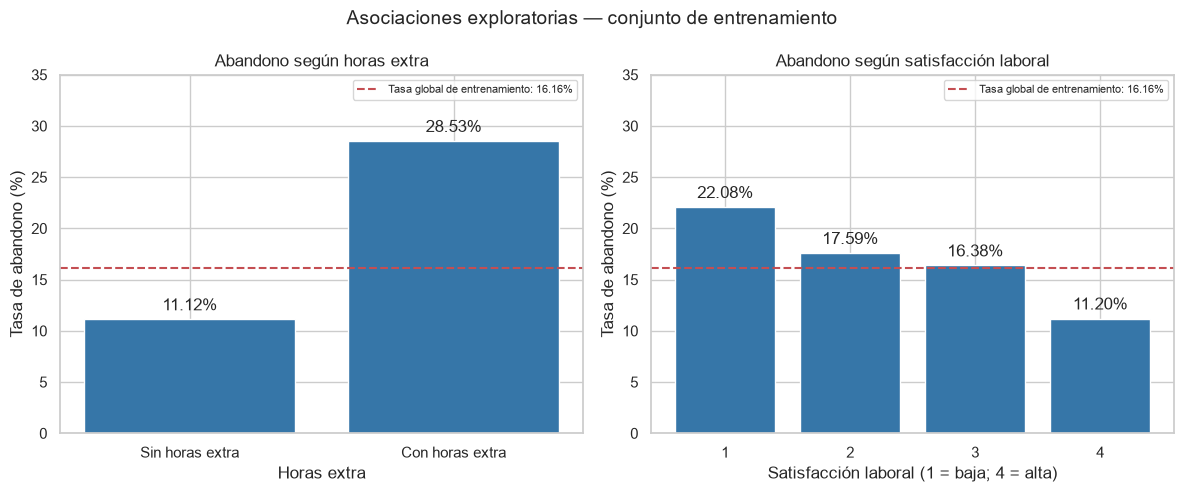

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", context="notebook")
tabla_overtime = resumen_abandono_por_grupo(
    df_train_modelo, "OverTime"
)
tabla_satisfaccion = resumen_abandono_por_grupo(
    df_train_modelo, "JobSatisfaction"
)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
configuraciones = [
    (
        axes[0],
        tabla_overtime,
        ["Sin horas extra", "Con horas extra"],
        "Abandono según horas extra",
        "Horas extra"
    ),
    (
        axes[1],
        tabla_satisfaccion,
        [str(nivel) for nivel in tabla_satisfaccion.index],
        "Abandono según satisfacción laboral",
        "Satisfacción laboral (1 = baja; 4 = alta)"
    )
]
tasa_global_train = y_train.mean() * 100
for ax, tabla, etiquetas, titulo, eje_x in configuraciones:
    barras = ax.bar(
        etiquetas,
        tabla["Tasa de abandono (%)"],
        color="#3676A8"
    )
    ax.bar_label(
        barras,
        labels=[
            f"{tasa:.2f}%"
            for tasa in tabla["Tasa de abandono (%)"]
        ],
        padding=4
    )
    ax.axhline(
        tasa_global_train,
        color="#C44E52",
        linestyle="--",
        label=f"Tasa global de entrenamiento: {tasa_global_train:.2f}%"
    )
    ax.set_title(titulo)
    ax.set_xlabel(eje_x)
    ax.set_ylabel("Tasa de abandono (%)")
    ax.set_ylim(0, 35)
    ax.legend(fontsize=8)
fig.suptitle(
    "Asociaciones exploratorias — conjunto de entrenamiento",
    fontsize=14
)
plt.tight_layout()
plt.show()


### Hallazgos exploratorios
En entrenamiento hay 190 casos de abandono entre 1.176 empleados
(16,16%).
**Horas extra:** el grupo con horas extra presenta una tasa de
abandono de 28,53% (97 de 340), frente a 11,12% (93 de 836)
en el grupo sin horas extra. La diferencia es de 17,41 puntos
porcentuales.
**Satisfacción laboral:** las tasas de abandono disminuyen
progresivamente entre los niveles 1 y 4: 22,08%, 17,59%,
16,38% y 11,20%, respectivamente.
Estas comparaciones son descriptivas y no controlan por otras
variables. No demuestran causalidad ni garantizan que las mismas
diferencias se reproduzcan en otra población.
Los hallazgos orientan la comprensión del problema, pero no se
utilizan por sí solos para elegir el modelo.

## 6. Exploración de variables numéricas
Comparamos la distribución de ingresos mensuales, antigüedad,
edad y distancia al trabajo entre empleados que permanecen
y empleados que abandonan.
Mostramos medias, medianas y diagramas de caja. La mediana
complementa la media porque es menos sensible a valores extremos.
Las diferencias son descriptivas y no implican causalidad.
No eliminamos observaciones únicamente porque aparezcan como
valores extremos en un gráfico.


Resumen de variables numéricas — entrenamiento:
          MonthlyIncome         YearsAtCompany           Age        DistanceFromHome       
                   mean  median           mean median   mean median             mean median
Grupo                                                                                      
Permanece       6871.64  5237.5           7.46    6.0  37.74   36.0             9.05    7.0
Abandona        4843.88  3373.0           4.90    3.0  33.13   31.0            10.97    9.0


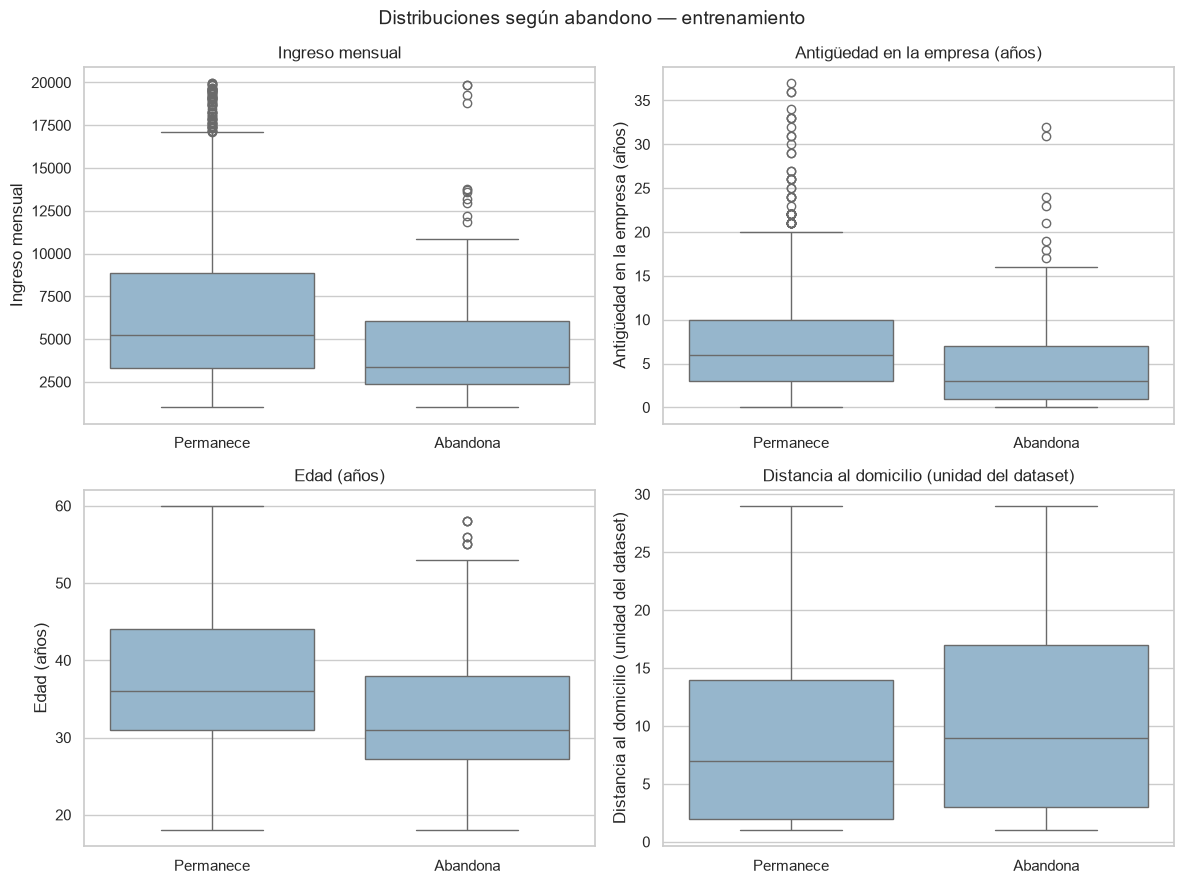

In [8]:
variables_eda = [
    "MonthlyIncome",
    "YearsAtCompany",
    "Age",
    "DistanceFromHome"
]
etiquetas = {
    "MonthlyIncome": "Ingreso mensual",
    "YearsAtCompany": "Antigüedad en la empresa (años)",
    "Age": "Edad (años)",
    "DistanceFromHome": "Distancia al domicilio (unidad del dataset)"
}
# Copia exclusiva para visualización: no modifica los datos de modelado.
datos_eda = df_train_modelo.copy()
datos_eda["Grupo"] = datos_eda["Attrition"].map({
    0: "Permanece",
    1: "Abandona"
})
orden_grupos = ["Permanece", "Abandona"]
resumen_numericas = (
    datos_eda
    .groupby("Grupo")[variables_eda]
    .agg(["mean", "median"])
    .reindex(orden_grupos)
    .round(2)
)
print("Resumen de variables numéricas — entrenamiento:")
print(resumen_numericas.to_string())
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, variable in zip(axes.flat, variables_eda):
    sns.boxplot(
        data=datos_eda,
        x="Grupo",
        y=variable,
        order=orden_grupos,
        color="#8DB8D5",
        ax=ax
    )
    ax.set_title(etiquetas[variable])
    ax.set_xlabel("")
    ax.set_ylabel(etiquetas[variable])
fig.suptitle(
    "Distribuciones según abandono — entrenamiento",
    fontsize=14
)
plt.tight_layout()
plt.show()


### Hallazgos sobre variables numéricas
En el conjunto de entrenamiento observamos:
- **Ingreso mensual:** la mediana es 3.373 entre quienes abandonan
  y 5.237,5 entre quienes permanecen.
- **Antigüedad:** la mediana es 3 años entre quienes abandonan
  y 6 años entre quienes permanecen.
- **Edad:** la mediana es 31 años entre quienes abandonan
  y 36 años entre quienes permanecen.
- **Distancia al domicilio:** la mediana es 9 entre quienes
  abandonan y 7 entre quienes permanecen, en las unidades
  registradas por el dataset.
Las medias presentan las mismas direcciones que las medianas.
En ingresos, las medias superan a las medianas en ambos grupos,
lo que es compatible con distribuciones asimétricas hacia
valores altos.
Estas diferencias describen asociaciones individuales, sin
controlar por otras características. No demuestran causalidad
ni permiten anticipar por sí solas qué empleado abandonará.
Por tratarse de datos ficticios, no deben interpretarse como
evidencia sobre una empresa real.

## 7. Preprocesamiento para Machine Learning
Aplicaremos dos transformaciones:
- Variables numéricas: estandarización con StandardScaler.
- Variables categóricas de texto: One-Hot Encoding.
Las escalas ordinales registradas como números se conservarán
como numéricas en esta primera comparación. En Regresión
Logística esto supone un efecto lineal por incremento de nivel
sobre el log-odds, una simplificación que documentamos.
El preprocesamiento se integrará dentro del pipeline de cada
modelo. Durante la validación cruzada, sus parámetros se
aprenderán exclusivamente con el entrenamiento de cada fold.
No ajustamos transformaciones sobre el dataset completo ni
sobre el conjunto de test.


In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
columnas_numericas = (
    X_train_modelo
    .select_dtypes(include=np.number)
    .columns
    .tolist()
)
columnas_categoricas = (
    X_train_modelo
    .select_dtypes(exclude=np.number)
    .columns
    .tolist()
)
# Comprobamos que todas las variables estén contempladas.
assert (
    len(columnas_numericas) + len(columnas_categoricas)
    == X_train_modelo.shape[1]
)
preprocesador = ColumnTransformer(
    transformers=[
        ("numericas", StandardScaler(), columnas_numericas),
        (
            "categoricas",
            OneHotEncoder(handle_unknown="ignore"),
            columnas_categoricas
        )
    ],
    remainder="drop"
)
print(f"Variables numéricas: {len(columnas_numericas)}")
print(columnas_numericas)
print(f"\nVariables categóricas: {len(columnas_categoricas)}")
print(columnas_categoricas)
print("\nPreprocesador definido, todavía sin ajustar.")

Variables numéricas: 23
['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Variables categóricas: 7
['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']

Preprocesador definido, todavía sin ajustar.


## 8. Baseline: Regresión Logística
El baseline será una Regresión Logística sin balanceo de clases,
con umbral de clasificación 0,5.
La evaluamos mediante validación cruzada estratificada de
5 folds sobre el conjunto de entrenamiento.
En cada iteración:
1. Se ajusta el preprocesamiento con cuatro folds.
2. Se entrena el modelo con esos mismos datos.
3. Se evalúa sobre el fold restante.
Reportamos la media y la desviación estándar entre folds
para describir el desempeño y su variabilidad.
Priorizamos Recall, Precision, F1 y Average Precision (AP)
para Attrition = Yes. ROC-AUC y Accuracy son complementarias.
AP resume la curva Precision-Recall y se utiliza aquí como
medida resumen de esa curva; no es exactamente igual al área
calculada mediante integración trapezoidal.
El test permanece reservado para la evaluación final.

In [10]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (
    make_scorer,
    precision_score,
    recall_score,
    f1_score
)
# Copia independiente del preprocesador.
baseline = Pipeline([
    ("preprocesamiento", clone(preprocesador)),
    (
        "modelo",
        LogisticRegression(
            class_weight=None,
            max_iter=3000,
            random_state=RANDOM_STATE
        )
    )
])
# Reutilizaremos estas mismas particiones para comparar modelos.
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)
metricas_cv = {
    "Recall": make_scorer(
        recall_score, pos_label=1, zero_division=0
    ),
    "Precision": make_scorer(
        precision_score, pos_label=1, zero_division=0
    ),
    "F1": make_scorer(
        f1_score, pos_label=1, zero_division=0
    ),
    "AP": "average_precision",
    "ROC_AUC": "roc_auc",
    "Accuracy": "accuracy"
}
cv_baseline = cross_validate(
    estimator=baseline,
    X=X_train_modelo,
    y=y_train,
    cv=cv,
    scoring=metricas_cv,
    n_jobs=-1,
    error_score="raise"
)
print("Validación cruzada completada sin utilizar el test.")

Validación cruzada completada sin utilizar el test.


In [11]:
resultados_baseline_folds = pd.DataFrame({
    nombre: cv_baseline[f"test_{nombre}"]
    for nombre in metricas_cv
})
resultados_baseline_folds.index = pd.Index(
    range(1, 6), name="Fold"
)
resumen_baseline_cv = pd.DataFrame({
    "Media CV": resultados_baseline_folds.mean(),
    "Desviación estándar": resultados_baseline_folds.std(ddof=1)
})
print("REGRESIÓN LOGÍSTICA BASELINE — RESULTADOS POR FOLD")
print(resultados_baseline_folds.round(4).to_string())
print("\nRESUMEN DE VALIDACIÓN CRUZADA")
print(resumen_baseline_cv.round(4).to_string())
print(
    "\nPrevalencia de abandono en entrenamiento: "
    f"{y_train.mean():.2%}"
)

REGRESIÓN LOGÍSTICA BASELINE — RESULTADOS POR FOLD
      Recall  Precision      F1      AP  ROC_AUC  Accuracy
Fold                                                      
1     0.3947     0.7895  0.5263  0.6683   0.8203    0.8856
2     0.2895     0.6471  0.4000  0.5406   0.8195    0.8596
3     0.4737     0.7826  0.5902  0.6748   0.8603    0.8936
4     0.5789     0.8800  0.6984  0.7258   0.8857    0.9191
5     0.4737     0.7826  0.5902  0.6477   0.8102    0.8936

RESUMEN DE VALIDACIÓN CRUZADA
           Media CV  Desviación estándar
Recall       0.4421               0.1075
Precision    0.7763               0.0832
F1           0.5610               0.1092
AP           0.6514               0.0683
ROC_AUC      0.8392               0.0324
Accuracy     0.8903               0.0213

Prevalencia de abandono en entrenamiento: 16.16%


### Resultados del baseline
La Regresión Logística sin balanceo y con umbral 0,5 obtuvo,
en validación cruzada:
- Recall medio: 44,21%.
- Precision media: 77,63%.
- F1 medio: 0,5610.
- Average Precision media: 0,6514.
- ROC-AUC medio: 0,8392.
- Accuracy media: 89,03%.
El modelo presenta una Precision relativamente alta, pero detecta
menos de la mitad de los abandonos con el umbral predeterminado.
El Recall varía entre 28,95% y 57,89% entre folds, con una
desviación estándar de 10,75 puntos porcentuales. Esto evidencia
sensibilidad a la partición y aconseja prudencia al interpretar
diferencias pequeñas entre modelos.
Estos resultados pertenecen exclusivamente a validación cruzada
sobre entrenamiento. No representan el desempeño final en test.

## 9. Comparación inicial de modelos
Comparamos tres alternativas usando exactamente las mismas
particiones y métricas:
1. Regresión Logística sin balanceo: baseline.
2. Regresión Logística balanceada: aumenta el peso de la clase
   minoritaria durante el entrenamiento.
3. Random Forest balanceado: permite capturar relaciones no
   lineales e interacciones entre variables.
El balanceo no garantiza mejorar todas las métricas. Puede
aumentar la detección de abandonos a costa de más falsas alertas.
Esta primera comparación utiliza el umbral predeterminado 0,5.
Posteriormente evaluaremos umbrales con predicciones out-of-fold,
sin consultar el test.
Los pesos de clase se calculan a partir del entrenamiento
de cada fold.

In [12]:
from sklearn.ensemble import RandomForestClassifier
logistica_balanceada = Pipeline([
    ("preprocesamiento", clone(preprocesador)),
    (
        "modelo",
        LogisticRegression(
            class_weight="balanced",
            max_iter=3000,
            random_state=RANDOM_STATE
        )
    )
])
random_forest = Pipeline([
    ("preprocesamiento", clone(preprocesador)),
    (
        "modelo",
        RandomForestClassifier(
            n_estimators=500,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            # Evita paralelizar simultáneamente árboles y folds.
            n_jobs=1
        )
    )
])
modelos_ml = {
    "Logística baseline": baseline,
    "Logística balanceada": logistica_balanceada,
    "Random Forest": random_forest
}
# Reutilizamos el resultado ya calculado del baseline.
resultados_cv_modelos = {
    "Logística baseline": cv_baseline
}
for nombre, modelo in modelos_ml.items():
    if nombre in resultados_cv_modelos:
        continue
    print(f"Evaluando: {nombre}...")
    resultados_cv_modelos[nombre] = cross_validate(
        estimator=modelo,
        X=X_train_modelo,
        y=y_train,
        cv=cv,
        scoring=metricas_cv,
        n_jobs=-1,
        error_score="raise"
    )
print("Comparación completada. Test sin utilizar.")

Evaluando: Logística balanceada...
Evaluando: Random Forest...
Comparación completada. Test sin utilizar.


In [13]:
filas_comparacion = []
for nombre, resultado in resultados_cv_modelos.items():
    fila = {"Modelo": nombre}
    for metrica in metricas_cv:
        valores = resultado[f"test_{metrica}"]
        fila[f"{metrica} media"] = valores.mean()
        fila[f"{metrica} DE"] = valores.std(ddof=1)
    filas_comparacion.append(fila)
comparacion_cv = (
    pd.DataFrame(filas_comparacion)
    .set_index("Modelo")
)
for metrica in metricas_cv:
    print(f"\n{metrica.upper()} — VALIDACIÓN CRUZADA")
    print(
        comparacion_cv[
            [f"{metrica} media", f"{metrica} DE"]
        ].round(4).to_string()
    )


RECALL — VALIDACIÓN CRUZADA
                      Recall media  Recall DE
Modelo                                       
Logística baseline          0.4421     0.1075
Logística balanceada        0.7368     0.0696
Random Forest               0.3632     0.1043

PRECISION — VALIDACIÓN CRUZADA
                      Precision media  Precision DE
Modelo                                             
Logística baseline             0.7763        0.0832
Logística balanceada           0.3721        0.0424
Random Forest                  0.6410        0.1111

F1 — VALIDACIÓN CRUZADA
                      F1 media   F1 DE
Modelo                                
Logística baseline      0.5610  0.1092
Logística balanceada    0.4925  0.0376
Random Forest           0.4545  0.0921

AP — VALIDACIÓN CRUZADA
                      AP media   AP DE
Modelo                                
Logística baseline      0.6514  0.0683
Logística balanceada    0.6058  0.0914
Random Forest           0.5612  0.0610

ROC_AUC 

### Comparación inicial de modelos
La logística balanceada incrementa el Recall medio desde 44,21%
hasta 73,68%, una mejora de 29,47 puntos porcentuales respecto
del baseline en validación cruzada.
Sin embargo, la Precision disminuye desde 77,63% hasta 37,21%
y el F1 baja de 0,5610 a 0,4925. El mayor Recall se obtiene
a costa de más falsas alertas.
La logística sin balanceo presenta los mejores valores medios
de Average Precision, F1 y ROC-AUC entre las alternativas
evaluadas. Esto motiva explorar también su umbral de clasificación,
en lugar de asumir que el balanceo es necesariamente superior.
Random Forest no muestra una ventaja en esta comparación.
Su Recall con umbral 0,5 no describe por sí solo toda su
capacidad de priorización.
Las diferencias observadas no constituyen una prueba de
superioridad estadística. El test continúa reservado.

## 10. Priorización: Recall@20%
En cada fold de validación:
1. Ordenamos sus empleados por el score de abandono.
2. Seleccionamos el 20% con mayor score, redondeando hacia arriba.
3. Calculamos qué proporción de abandonos reales queda incluida.
La selección se realiza por separado dentro de cada fold,
evitando mezclar scores de modelos entrenados en folds distintos.
También reportamos:
- Precision@20%: proporción de abandonos dentro del grupo seleccionado.
- Lift: Recall@20% dividido por la fracción efectivamente seleccionada.
Una selección aleatoria capturaría, en expectativa, aproximadamente
el 20% de los abandonos. El redondeo puede hacer que la fracción
seleccionada sea ligeramente superior al 20%.
Este escenario representa priorización para revisión humana,
no una recomendación automática de acciones laborales.

In [14]:
from sklearn.model_selection import cross_val_predict
# Materializamos las mismas particiones para reutilizarlas.
particiones_cv = list(cv.split(X_train_modelo, y_train))
probabilidades_oof = {}
for nombre, modelo in modelos_ml.items():
    print(f"Generando predicciones OOF: {nombre}...")
    probabilidades_oof[nombre] = cross_val_predict(
        estimator=modelo,
        X=X_train_modelo,
        y=y_train,
        cv=particiones_cv,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]
filas_ranking = []
for nombre, probabilidades in probabilidades_oof.items():
    for numero_fold, (_, indices_val) in enumerate(
        particiones_cv, start=1
    ):
        y_fold = y_train.iloc[indices_val].to_numpy()
        prob_fold = probabilidades[indices_val]
        n_priorizados = int(np.ceil(0.20 * len(y_fold)))
        # Orden estable para resolver empates de manera reproducible.
        orden = np.argsort(-prob_fold, kind="stable")
        seleccionados = orden[:n_priorizados]
        abandonos_totales = int(y_fold.sum())
        abandonos_capturados = int(y_fold[seleccionados].sum())
        recall20 = abandonos_capturados / abandonos_totales
        precision20 = abandonos_capturados / n_priorizados
        fraccion_seleccionada = n_priorizados / len(y_fold)
        filas_ranking.append({
            "Modelo": nombre,
            "Fold": numero_fold,
            "Priorizados": n_priorizados,
            "Abandonos capturados": abandonos_capturados,
            "Abandonos totales": abandonos_totales,
            "Recall@20%": recall20,
            "Precision@20%": precision20,
            "Lift": recall20 / fraccion_seleccionada
        })
ranking_por_fold = pd.DataFrame(filas_ranking)
resumen_ranking_cv = (
    ranking_por_fold
    .groupby("Modelo", sort=False)
    .agg(
        Recall20_media=("Recall@20%", "mean"),
        Recall20_DE=("Recall@20%", "std"),
        Precision20_media=("Precision@20%", "mean"),
        Lift_medio=("Lift", "mean")
    )
)
print("\nPRIORIZACIÓN DEL 20% — VALIDACIÓN CRUZADA")
print(resumen_ranking_cv.round(4).to_string())

Generando predicciones OOF: Logística baseline...
Generando predicciones OOF: Logística balanceada...
Generando predicciones OOF: Random Forest...

PRIORIZACIÓN DEL 20% — VALIDACIÓN CRUZADA
                      Recall20_media  Recall20_DE  Precision20_media  Lift_medio
Modelo                                                                          
Logística baseline            0.6579       0.0322             0.5297      3.2785
Logística balanceada          0.6316       0.0416             0.5086      3.1478
Random Forest                 0.5789       0.0492             0.4661      2.8851


### Resultados de priorización
La Regresión Logística sin balanceo obtiene el mayor Recall@20%
medio: 65,79%, frente a 63,16% de la logística balanceada y
57,89% de Random Forest.
Su Precision@20% media es 52,97%: aproximadamente la mitad
de los empleados priorizados corresponde a casos de abandono.
El lift medio es 3,28 respecto de una selección aleatoria
de la misma proporción.
Por lo tanto, el balanceo no mejora necesariamente el ranking,
aunque aumente el Recall de clasificación con umbral 0,5.
Estos resultados corresponden a validación cruzada sobre
entrenamiento. No constituyen evidencia de utilidad real de
una intervención ni permiten tomar decisiones laborales.

## 11. Selección de modelo y umbral con predicciones OOF
Exploramos umbrales entre 0,05 y 0,95, en incrementos de 0,01,
utilizando las predicciones out-of-fold ya calculadas.
Criterio de selección:
1. Exigir un Recall medio por folds al menos 8 puntos
   porcentuales superior al baseline con umbral 0,5.
2. Entre las alternativas que cumplen, maximizar el F1 medio.
3. En caso de empate, preferir mayor Precision media.
El umbral permite modificar el equilibrio entre detección y
falsas alertas. No modifica las probabilidades ni el ranking:
AP, ROC-AUC y Recall@20% permanecen iguales para un mismo
modelo ya entrenado.
Los resultados OOF se utilizan para seleccionar la configuración.
Por ello, el desempeño de la configuración elegida sobre estos
mismos folds puede ser optimista. El test reservado se utilizará
después para su evaluación final, sin reajustar decisiones.

In [15]:
recall_base_cv = resultados_baseline_folds["Recall"].mean()
recall_objetivo_cv = recall_base_cv + 0.08
umbrales = np.round(np.arange(0.05, 0.951, 0.01), 2)
filas_umbrales = []
for nombre, probabilidades in probabilidades_oof.items():
    for umbral in umbrales:
        metricas_folds = []
        for _, indices_val in particiones_cv:
            y_real = y_train.iloc[indices_val].to_numpy()
            pred = (
                probabilidades[indices_val] >= umbral
            ).astype(int)
            metricas_folds.append({
                "Recall": recall_score(
                    y_real, pred, zero_division=0
                ),
                "Precision": precision_score(
                    y_real, pred, zero_division=0
                ),
                "F1": f1_score(
                    y_real, pred, zero_division=0
                )
            })
        tabla_folds = pd.DataFrame(metricas_folds)
        filas_umbrales.append({
            "Modelo": nombre,
            "Umbral": umbral,
            "Recall CV": tabla_folds["Recall"].mean(),
            "Recall DE": tabla_folds["Recall"].std(ddof=1),
            "Precision CV": tabla_folds["Precision"].mean(),
            "F1 CV": tabla_folds["F1"].mean()
        })
tabla_umbrales = pd.DataFrame(filas_umbrales)
tabla_umbrales["Mejora Recall pp"] = (
    tabla_umbrales["Recall CV"] - recall_base_cv
) * 100
# Pequeña tolerancia para comparaciones de números decimales.
candidatos_validos = (
    tabla_umbrales.loc[
        tabla_umbrales["Recall CV"] >= recall_objetivo_cv - 1e-12
    ]
    .sort_values(
        ["F1 CV", "Precision CV", "Modelo", "Umbral"],
        ascending=[False, False, True, True]
    )
    .reset_index(drop=True)
)
if candidatos_validos.empty:
    raise ValueError(
        "Ninguna configuración cumple el objetivo en validación."
    )
seleccion_ml = candidatos_validos.iloc[0].copy()
mejor_por_modelo = (
    candidatos_validos
    .drop_duplicates(subset="Modelo", keep="first")
)
print(f"Recall baseline CV: {recall_base_cv:.2%}")
print(f"Recall mínimo requerido CV: {recall_objetivo_cv:.2%}")
print("\nMEJOR CONFIGURACIÓN VÁLIDA POR MODELO")
print(mejor_por_modelo.round(4).to_string(index=False))
print("\nCONFIGURACIÓN SELECCIONADA EN VALIDACIÓN")
print(seleccion_ml.to_string())

Recall baseline CV: 44.21%
Recall mínimo requerido CV: 52.21%

MEJOR CONFIGURACIÓN VÁLIDA POR MODELO
              Modelo  Umbral  Recall CV  Recall DE  Precision CV  F1 CV  Mejora Recall pp
  Logística baseline    0.37     0.6000     0.0754        0.6503 0.6221           15.7895
Logística balanceada    0.71     0.5789     0.0853        0.5903 0.5812           13.6842
       Random Forest    0.32     0.6737     0.0960        0.4263 0.5189           23.1579

CONFIGURACIÓN SELECCIONADA EN VALIDACIÓN
Modelo              Logística baseline
Umbral                            0.37
Recall CV                          0.6
Recall DE                     0.075357
Precision CV                  0.650344
F1 CV                         0.622127
Mejora Recall pp             15.789474


### Configuración seleccionada en validación
Según el criterio definido, seleccionamos la Regresión Logística
sin balanceo con umbral 0,37.
Con este umbral alcanza:
- Recall medio: 60,00%.
- Precision media: 65,03%.
- F1 medio: 0,6221.
Frente al baseline con umbral 0,5, el Recall aumenta 15,79 puntos
porcentuales y el F1 mejora, a costa de una menor Precision.
La logística balanceada y Random Forest también encuentran
umbrales que cumplen el requisito de Recall, pero presentan
un F1 medio inferior.
La configuración se seleccionó utilizando entrenamiento y
predicciones out-of-fold. Estos resultados son de selección,
no una estimación independiente del desempeño final.
El objetivo de mejora se comprobará posteriormente en test,
comparando el baseline y la configuración fijada sobre los
mismos empleados. No se garantiza que la mejora de validación
se reproduzca allí.

Configuración ML fijada:
modelo: Logística baseline
umbral: 0.37
criterio: Mayor F1 medio CV entre configuraciones con mejora de Recall de al menos 8 puntos porcentuales
random_state: 42


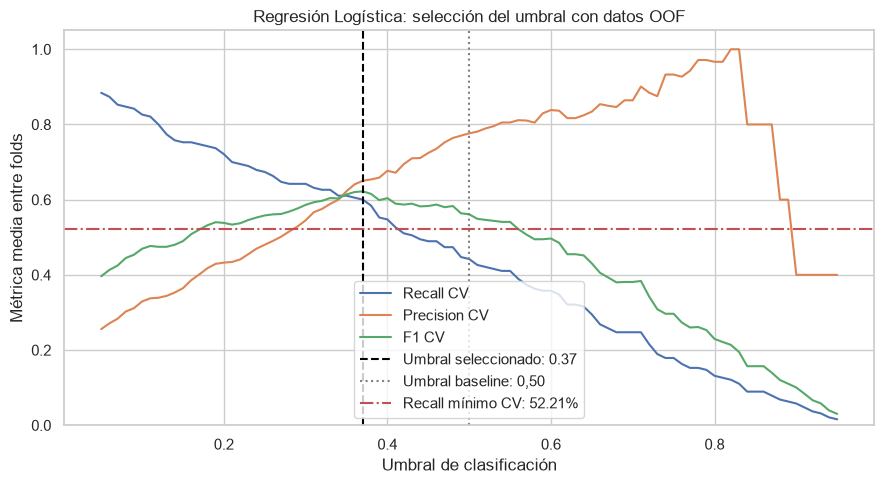

In [16]:
# Configuración seleccionada exclusivamente con entrenamiento.
nombre_seleccionado_ml = str(seleccion_ml["Modelo"])
umbral_seleccionado_ml = float(seleccion_ml["Umbral"])
# clone crea un pipeline independiente y todavía sin entrenar.
modelo_seleccionado_ml = clone(
    modelos_ml[nombre_seleccionado_ml]
)
configuracion_ml = {
    "modelo": nombre_seleccionado_ml,
    "umbral": umbral_seleccionado_ml,
    "criterio": (
        "Mayor F1 medio CV entre configuraciones con mejora "
        "de Recall de al menos 8 puntos porcentuales"
    ),
    "random_state": RANDOM_STATE
}
print("Configuración ML fijada:")
for clave, valor in configuracion_ml.items():
    print(f"{clave}: {valor}")
# Curvas calculadas previamente; no volvemos a entrenar.
curvas = (
    tabla_umbrales.loc[
        tabla_umbrales["Modelo"] == nombre_seleccionado_ml
    ]
    .sort_values("Umbral")
)
fig, ax = plt.subplots(figsize=(9, 5))
for metrica in ["Recall CV", "Precision CV", "F1 CV"]:
    ax.plot(
        curvas["Umbral"],
        curvas[metrica],
        label=metrica
    )
ax.axvline(
    umbral_seleccionado_ml,
    color="black",
    linestyle="--",
    label=f"Umbral seleccionado: {umbral_seleccionado_ml:.2f}"
)
ax.axvline(
    0.50,
    color="gray",
    linestyle=":",
    label="Umbral baseline: 0,50"
)
ax.axhline(
    recall_objetivo_cv,
    color="#C44E52",
    linestyle="-.",
    label=f"Recall mínimo CV: {recall_objetivo_cv:.2%}"
)
ax.set(
    title="Regresión Logística: selección del umbral con datos OOF",
    xlabel="Umbral de clasificación",
    ylabel="Métrica media entre folds",
    ylim=(0, 1.05)
)
ax.legend(loc="best")
plt.tight_layout()
plt.show()

## 12. Extensión: Deep Learning
Evaluamos si una red neuronal aporta una mejora útil para este
problema tabular y de tamaño reducido.
Dividimos el entrenamiento original en:
- Entrenamiento de la red: aprendizaje de pesos.
- Validación interna: seguimiento del entrenamiento y Early Stopping.
El test permanece reservado.
El preprocesamiento se ajusta nuevamente, utilizando solo el
subconjunto de entrenamiento de la red.
Esta extensión no tiene exactamente el mismo esquema de evaluación
que la comparación ML de 5 folds. Sus resultados de validación
no se interpretarán como una comparación directa y concluyente
contra las medias de validación cruzada.

In [17]:
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


In [18]:
import tensorflow as tf
from tensorflow import keras
# Fija las semillas de Python, NumPy y TensorFlow.
keras.utils.set_random_seed(RANDOM_STATE)
X_dl_train_raw, X_dl_val_raw, y_dl_train, y_dl_val = (
    train_test_split(
        X_train_modelo,
        y_train,
        test_size=0.20,
        stratify=y_train,
        random_state=RANDOM_STATE
    )
)
# Verificar que no se solapen los subconjuntos.
assert X_dl_train_raw.index.intersection(
    X_dl_val_raw.index
).empty
assert X_dl_train_raw.index.intersection(X_test.index).empty
assert X_dl_val_raw.index.intersection(X_test.index).empty
preprocesador_dl = clone(preprocesador)
# Ajuste exclusivamente con entrenamiento de la red.
X_dl_train = preprocesador_dl.fit_transform(X_dl_train_raw)
X_dl_val = preprocesador_dl.transform(X_dl_val_raw)
# Convertir a matrices densas si fuera necesario.
if hasattr(X_dl_train, "toarray"):
    X_dl_train = X_dl_train.toarray()
if hasattr(X_dl_val, "toarray"):
    X_dl_val = X_dl_val.toarray()
X_dl_train = np.asarray(X_dl_train, dtype="float32")
X_dl_val = np.asarray(X_dl_val, dtype="float32")
y_dl_train_array = y_dl_train.to_numpy(dtype="float32")
y_dl_val_array = y_dl_val.to_numpy(dtype="float32")
print("Versión de TensorFlow:", tf.__version__)
print("Entrenamiento DNN:", X_dl_train.shape)
print("Validación DNN:", X_dl_val.shape)
print(
    "Abandonos en entrenamiento DNN:",
    int(y_dl_train_array.sum())
)
print(
    "Abandonos en validación DNN:",
    int(y_dl_val_array.sum())
)
print("\nTest sin transformar ni utilizar en este bloque.")

Versión de TensorFlow: 2.22.0-rc0
Entrenamiento DNN: (940, 51)
Validación DNN: (236, 51)
Abandonos en entrenamiento DNN: 152
Abandonos en validación DNN: 38

Test sin transformar ni utilizar en este bloque.


## 13. DNN con Early Stopping
Arquitectura:
- Entrada: variables transformadas.
- Capa oculta: 36 neuronas, activación ReLU.
- Capa oculta: 12 neuronas, activación ReLU.
- Salida: 1 neurona, activación sigmoide.
Utilizamos binary crossentropy y el optimizador RMSprop.
Early Stopping detiene el entrenamiento si la pérdida de
validación no mejora durante 15 épocas y recupera los pesos
de la mejor época.
ModelCheckpoint guarda el mejor modelo según esa misma pérdida.
Esta primera red no utiliza pesos de clase. Precision y Recall
durante el entrenamiento se calculan con umbral 0,5.

Model: "DNN_Attrition_EarlyStopping"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 36)             │         1,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 12)             │           444 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            13 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,329 (9.10 KB)

 Trainable params: 2,329 (9.10 KB)

 Non-trainable params: 0 (0.00 B)


Épocas ejecutadas: 30
Época con menor pérdida de validación: 15
Mejor pérdida de validación: 0.3735


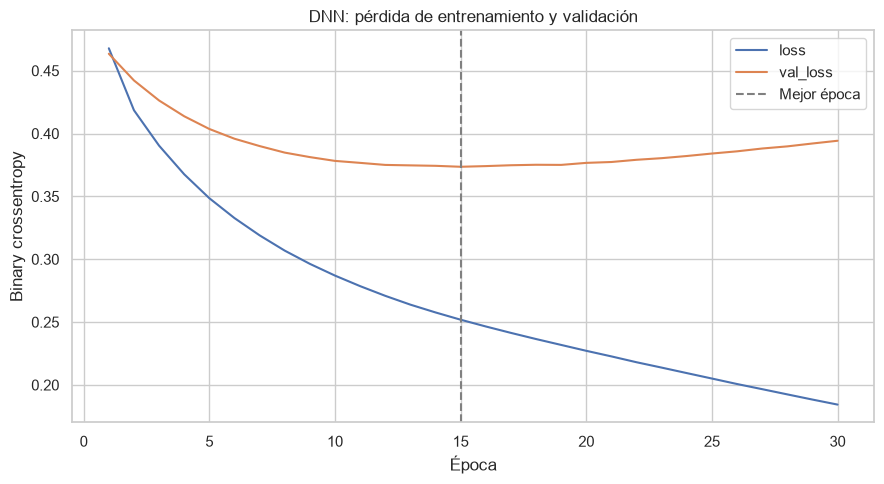

In [19]:
keras.utils.set_random_seed(RANDOM_STATE)
carpeta_modelos = Path("models")
carpeta_modelos.mkdir(exist_ok=True)
ruta_checkpoint_dnn = carpeta_modelos / "dnn_early_best.keras"
dnn_early = keras.Sequential([
    keras.layers.Input(shape=(X_dl_train.shape[1],)),
    keras.layers.Dense(36, activation="relu"),
    keras.layers.Dense(12, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid")
], name="DNN_Attrition_EarlyStopping")
dnn_early.compile(
    optimizer=keras.optimizers.RMSprop(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.AUC(name="roc_auc"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall")
    ]
)
callbacks_dnn = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=15,
        restore_best_weights=True
    ),
    keras.callbacks.ModelCheckpoint(
        filepath=str(ruta_checkpoint_dnn),
        monitor="val_loss",
        mode="min",
        save_best_only=True
    )
]
dnn_early.summary()
historial_dnn = dnn_early.fit(
    X_dl_train,
    y_dl_train_array,
    validation_data=(X_dl_val, y_dl_val_array),
    epochs=300,
    batch_size=64,
    callbacks=callbacks_dnn,
    verbose=0
)
historial_dnn_df = pd.DataFrame(historial_dnn.history)
historial_dnn_df.index = pd.RangeIndex(
    1, len(historial_dnn_df) + 1, name="Época"
)
mejor_epoca_dnn = int(historial_dnn_df["val_loss"].idxmin())
print("\nÉpocas ejecutadas:", len(historial_dnn_df))
print("Época con menor pérdida de validación:", mejor_epoca_dnn)
print(
    "Mejor pérdida de validación:",
    round(historial_dnn_df["val_loss"].min(), 4)
)
historial_dnn_df[["loss", "val_loss"]].plot(
    figsize=(9, 5),
    title="DNN: pérdida de entrenamiento y validación"
)
plt.axvline(
    mejor_epoca_dnn,
    color="gray",
    linestyle="--",
    label="Mejor época"
)
plt.xlabel("Época")
plt.ylabel("Binary crossentropy")
plt.legend()
plt.tight_layout()
plt.show()

### Evidencia de sobreajuste
La pérdida de validación alcanza su mínimo en la época 15.
Después aumenta mientras la pérdida de entrenamiento continúa
disminuyendo, un patrón compatible con sobreajuste.
Early Stopping recupera los pesos de la mejor época y evita
conservar los de la última. Esto limita el sobreajuste, pero
no garantiza que la red supere a los modelos tradicionales.


### Resultado del entrenamiento y evaluación interna
La DNN ejecutó 30 épocas. La menor pérdida de validación fue
0,3735 en la época 15. Early Stopping recuperó los pesos de
esa época.
Evaluamos inicialmente con umbral 0,5 sobre validación interna.
Este conjunto también se utilizó para seleccionar la época,
por lo que sus resultados no son una evaluación final independiente.
El test continúa reservado. No comparamos estos valores como
si fueran equivalentes a las medias de validación cruzada de ML.

In [20]:
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix
)
# dnn_early ya contiene los pesos recuperados por Early Stopping.
prob_dnn_val = dnn_early.predict(
    X_dl_val, verbose=0
).reshape(-1)
pred_dnn_val = (prob_dnn_val >= 0.50).astype(int)
# Ranking del 20% superior en la validación interna.
n_priorizados_val = int(np.ceil(0.20 * len(y_dl_val_array)))
orden_val = np.argsort(-prob_dnn_val, kind="stable")
seleccion_val = orden_val[:n_priorizados_val]
abandonos_val = int(y_dl_val_array.sum())
capturados_val = int(
    y_dl_val_array[seleccion_val].sum()
)
resultado_dnn_val = pd.Series({
    "Accuracy": accuracy_score(
        y_dl_val_array, pred_dnn_val
    ),
    "Recall": recall_score(
        y_dl_val_array, pred_dnn_val, zero_division=0
    ),
    "Precision": precision_score(
        y_dl_val_array, pred_dnn_val, zero_division=0
    ),
    "F1": f1_score(
        y_dl_val_array, pred_dnn_val, zero_division=0
    ),
    "AP": average_precision_score(
        y_dl_val_array, prob_dnn_val
    ),
    "ROC_AUC": roc_auc_score(
        y_dl_val_array, prob_dnn_val
    ),
    "Recall@20%": capturados_val / abandonos_val
}, name="DNN Early Stopping — validación interna")
print(resultado_dnn_val.round(4).to_string())
print("\nPriorización en validación interna:")
print("Empleados priorizados:", n_priorizados_val)
print("Abandonos capturados:", capturados_val)
print("Abandonos totales:", abandonos_val)
matriz_dnn_val = pd.DataFrame(
    confusion_matrix(
        y_dl_val_array, pred_dnn_val, labels=[0, 1]
    ),
    index=["Real: permanece", "Real: abandona"],
    columns=["Predice: permanece", "Predice: abandona"]
)
print("\nMatriz de confusión — umbral 0,50:")
print(matriz_dnn_val.to_string())

Accuracy      0.8814
Recall        0.3421
Precision     0.8125
F1            0.4815
AP            0.5743
ROC_AUC       0.7735
Recall@20%    0.5526

Priorización en validación interna:
Empleados priorizados: 48
Abandonos capturados: 21
Abandonos totales: 38

Matriz de confusión — umbral 0,50:
                 Predice: permanece  Predice: abandona
Real: permanece                 195                  3
Real: abandona                   25                 13


### Evaluación de la DNN con Early Stopping
En validación interna y con umbral 0,5, la red obtiene:
- Recall: 34,21%.
- Precision: 81,25%.
- F1: 0,4815.
- Average Precision: 0,5743.
- ROC-AUC: 0,7735.
Detecta 13 de los 38 abandonos y genera 3 falsas alertas.
Su alta Precision convive con una baja detección de la clase
positiva en este punto de operación.
Al priorizar 48 de los 236 empleados de validación, captura
21 abandonos: Recall@20% de 55,26%.
Estos resultados pertenecen a la validación interna utilizada
para seleccionar la época. No constituyen una evaluación
independiente ni son directamente equivalentes a las medias
de validación cruzada de los modelos ML.


## 14. DNN con Dropout y Early Stopping
Conservamos la arquitectura, el optimizador, el batch size y
la partición de la primera red. Agregamos Dropout de 0,30
después de cada capa oculta.
Durante el entrenamiento, Dropout desactiva aleatoriamente
una fracción de las activaciones para reducir la dependencia
de combinaciones particulares de neuronas.
Evaluamos si esta regularización mejora el comportamiento
en validación. No asumimos que necesariamente lo hará.
El test continúa reservado.

Épocas ejecutadas: 48
Mejor época: 33
Menor pérdida de validación: 0.3597


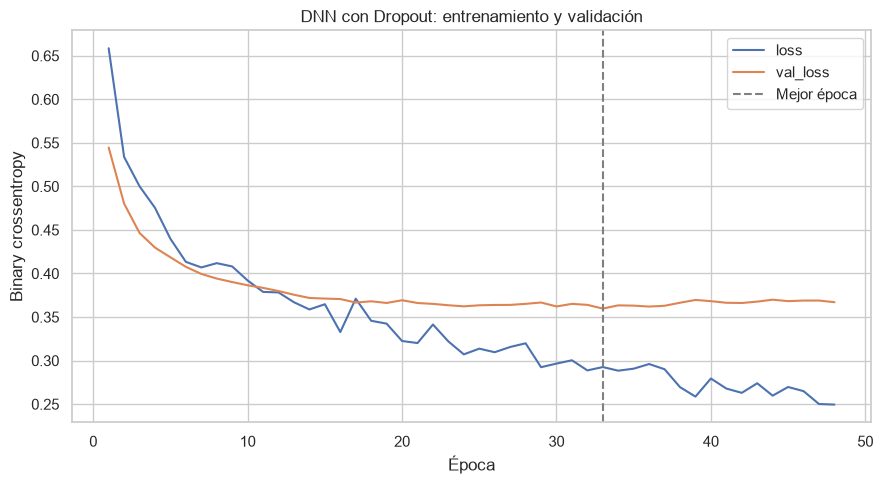

In [21]:
keras.utils.set_random_seed(RANDOM_STATE)
ruta_checkpoint_dropout = (
    carpeta_modelos / "dnn_dropout_best.keras"
)
dnn_dropout = keras.Sequential([
    keras.layers.Input(shape=(X_dl_train.shape[1],)),
    keras.layers.Dense(36, activation="relu"),
    keras.layers.Dropout(0.30),
    keras.layers.Dense(12, activation="relu"),
    keras.layers.Dropout(0.30),
    keras.layers.Dense(1, activation="sigmoid")
], name="DNN_Attrition_Dropout")
dnn_dropout.compile(
    optimizer=keras.optimizers.RMSprop(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.AUC(name="roc_auc"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall")
    ]
)
callbacks_dropout = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=15,
        restore_best_weights=True
    ),
    keras.callbacks.ModelCheckpoint(
        filepath=str(ruta_checkpoint_dropout),
        monitor="val_loss",
        mode="min",
        save_best_only=True
    )
]
historial_dropout = dnn_dropout.fit(
    X_dl_train,
    y_dl_train_array,
    validation_data=(X_dl_val, y_dl_val_array),
    epochs=300,
    batch_size=64,
    callbacks=callbacks_dropout,
    verbose=0
)
historial_dropout_df = pd.DataFrame(historial_dropout.history)
historial_dropout_df.index = pd.RangeIndex(
    1, len(historial_dropout_df) + 1, name="Época"
)
mejor_epoca_dropout = int(
    historial_dropout_df["val_loss"].idxmin()
)
print("Épocas ejecutadas:", len(historial_dropout_df))
print("Mejor época:", mejor_epoca_dropout)
print(
    "Menor pérdida de validación:",
    round(historial_dropout_df["val_loss"].min(), 4)
)
historial_dropout_df[["loss", "val_loss"]].plot(
    figsize=(9, 5),
    title="DNN con Dropout: entrenamiento y validación"
)
plt.axvline(
    mejor_epoca_dropout,
    color="gray",
    linestyle="--",
    label="Mejor época"
)
plt.xlabel("Época")
plt.ylabel("Binary crossentropy")
plt.legend()
plt.tight_layout()
plt.show()


In [22]:
# El modelo conserva los pesos de la mejor época.
prob_dropout_val = dnn_dropout.predict(
    X_dl_val, verbose=0
).reshape(-1)
pred_dropout_val = (prob_dropout_val >= 0.50).astype(int)
# Priorización del 20% de mayor score.
orden_dropout_val = np.argsort(
    -prob_dropout_val, kind="stable"
)
seleccion_dropout_val = orden_dropout_val[:n_priorizados_val]
capturados_dropout_val = int(
    y_dl_val_array[seleccion_dropout_val].sum()
)
resultado_dropout_val = pd.Series({
    "Accuracy": accuracy_score(
        y_dl_val_array, pred_dropout_val
    ),
    "Recall": recall_score(
        y_dl_val_array, pred_dropout_val, zero_division=0
    ),
    "Precision": precision_score(
        y_dl_val_array, pred_dropout_val, zero_division=0
    ),
    "F1": f1_score(
        y_dl_val_array, pred_dropout_val, zero_division=0
    ),
    "AP": average_precision_score(
        y_dl_val_array, prob_dropout_val
    ),
    "ROC_AUC": roc_auc_score(
        y_dl_val_array, prob_dropout_val
    ),
    "Recall@20%": capturados_dropout_val / abandonos_val
}, name="DNN Dropout — validación interna")
comparacion_dnn_val = pd.DataFrame({
    "DNN Early Stopping": resultado_dnn_val,
    "DNN Dropout + Early Stopping": resultado_dropout_val
})
print("COMPARACIÓN — MISMA VALIDACIÓN INTERNA")
print(comparacion_dnn_val.round(4).to_string())
print("\nPriorización con Dropout:")
print("Empleados priorizados:", n_priorizados_val)
print("Abandonos capturados:", capturados_dropout_val)
print("Abandonos totales:", abandonos_val)
matriz_dropout_val = pd.DataFrame(
    confusion_matrix(
        y_dl_val_array, pred_dropout_val, labels=[0, 1]
    ),
    index=["Real: permanece", "Real: abandona"],
    columns=["Predice: permanece", "Predice: abandona"]
)
print("\nMatriz de confusión con Dropout — umbral 0,50:")
print(matriz_dropout_val.to_string())

COMPARACIÓN — MISMA VALIDACIÓN INTERNA
            DNN Early Stopping  DNN Dropout + Early Stopping
Accuracy                0.8814                        0.8644
Recall                  0.3421                        0.3158
Precision               0.8125                        0.6667
F1                      0.4815                        0.4286
AP                      0.5743                        0.5891
ROC_AUC                 0.7735                        0.7953
Recall@20%              0.5526                        0.6316

Priorización con Dropout:
Empleados priorizados: 48
Abandonos capturados: 24
Abandonos totales: 38

Matriz de confusión con Dropout — umbral 0,50:
                 Predice: permanece  Predice: abandona
Real: permanece                 192                  6
Real: abandona                   26                 12


### Entrenamiento de la DNN con Dropout
La red con Dropout ejecutó 48 épocas y alcanzó su menor
pérdida de validación en la época 33: 0,3597, frente a 0,3735
de la red sin Dropout.
Early Stopping recuperó los pesos de la mejor época.
La menor pérdida es una señal favorable en esta ejecución,
pero no implica necesariamente mejores métricas de clasificación
o priorización. Estas se evalúan por separado.
Ambas redes utilizan la misma validación interna, que también
interviene en la selección de la época. Las diferencias pueden
depender de la aleatoriedad del entrenamiento y no demuestran
por sí solas una ventaja generalizable de Dropout.
El test continúa reservado.


### Comparación de las redes neuronales
En la misma validación interna, la red con Dropout mejora
Average Precision (0,5891 frente a 0,5743), ROC-AUC
(0,7953 frente a 0,7735) y Recall@20% (63,16% frente a 55,26%).
Al priorizar 48 empleados, captura 24 de los 38 abandonos,
frente a 21 capturados por la red sin Dropout.
Sin embargo, con umbral 0,5 presenta menor Recall, Precision
y F1. Esto muestra que mejorar el ranking no garantiza
mejorar la clasificación con un umbral fijo.
La comparación corresponde a una sola partición y ejecución.
No demuestra una ventaja generalizable de Dropout.
Las redes se mantienen como extensión exploratoria. No se
reemplaza la configuración principal de Machine Learning
comparando estas métricas con las medias de validación cruzada,
porque los esquemas de evaluación son diferentes.

## 15. Evaluación final sobre test reservado
Antes de consultar el test fijamos:
- Referencia: Regresión Logística sin balanceo, umbral 0,50.
- Configuración principal: Regresión Logística sin balanceo,
  umbral 0,37, seleccionado mediante predicciones OOF.
- Extensión exploratoria: las dos DNN con los pesos elegidos
  por Early Stopping y umbral 0,50.
La logística se ajusta con los 1.176 registros de entrenamiento.
Las redes conservan el entrenamiento y preprocesamiento usados
en su validación interna; no se reentrenan en este bloque.
Por tanto, la comparación ML frente a DL describe estos
procedimientos concretos, no una superioridad general de una
familia de algoritmos: las redes aprendieron sus pesos con
menos registros que la logística.
Comprobamos si la configuración principal mejora el Recall
del baseline en al menos 8 puntos porcentuales sobre test.
Las decisiones quedan fijadas. Los resultados de test se
reportarán aunque no se cumpla el objetivo.

In [23]:
# Entrenar la configuración principal con todo entrenamiento.
modelo_seleccionado_ml.fit(X_train_modelo, y_train)
prob_log_test = modelo_seleccionado_ml.predict_proba(
    X_test_modelo
)[:, 1]
# Transformar test con el preprocesador ya ajustado de las DNN.
X_dl_test = preprocesador_dl.transform(X_test_modelo)
if hasattr(X_dl_test, "toarray"):
    X_dl_test = X_dl_test.toarray()
X_dl_test = np.asarray(X_dl_test, dtype="float32")
prob_early_test = dnn_early.predict(
    X_dl_test, verbose=0
).reshape(-1)
prob_dropout_test = dnn_dropout.predict(
    X_dl_test, verbose=0
).reshape(-1)
def evaluar_test(nombre, y_real, probabilidades, umbral):
    y_real = np.asarray(y_real, dtype=int)
    probabilidades = np.asarray(probabilidades)
    predicciones = (probabilidades >= umbral).astype(int)
    n_priorizados = int(np.ceil(0.20 * len(y_real)))
    orden = np.argsort(-probabilidades, kind="stable")
    capturados = int(y_real[orden[:n_priorizados]].sum())
    positivos = int(y_real.sum())
    tn, fp, fn, tp = confusion_matrix(
        y_real, predicciones, labels=[0, 1]
    ).ravel()
    return {
        "Modelo": nombre,
        "Umbral": umbral,
        "Recall": recall_score(
            y_real, predicciones, zero_division=0
        ),
        "Precision": precision_score(
            y_real, predicciones, zero_division=0
        ),
        "F1": f1_score(
            y_real, predicciones, zero_division=0
        ),
        "AP": average_precision_score(y_real, probabilidades),
        "ROC_AUC": roc_auc_score(y_real, probabilidades),
        "Accuracy": accuracy_score(y_real, predicciones),
        "Recall@20%": capturados / positivos,
        "Priorizados": n_priorizados,
        "Capturados@20%": capturados,
        "Abandonos totales": positivos,
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    }
resultados_test = pd.DataFrame([
    evaluar_test(
        "Logística baseline",
        y_test, prob_log_test, 0.50
    ),
    evaluar_test(
        "Logística seleccionada",
        y_test, prob_log_test, umbral_seleccionado_ml
    ),
    evaluar_test(
        "DNN Early Stopping",
        y_test, prob_early_test, 0.50
    ),
    evaluar_test(
        "DNN Dropout + Early Stopping",
        y_test, prob_dropout_test, 0.50
    )
]).set_index("Modelo")
columnas_metricas = [
    "Umbral", "Recall", "Precision", "F1",
    "AP", "ROC_AUC", "Accuracy", "Recall@20%"
]
print("EVALUACIÓN FINAL — TEST RESERVADO")
print(resultados_test[columnas_metricas].round(4).to_string())
print("\nCONTEOS Y PRIORIZACIÓN")
print(
    resultados_test[[
        "TN", "FP", "FN", "TP",
        "Priorizados", "Capturados@20%", "Abandonos totales"
    ]].to_string()
)
mejora_test_pp = 100 * (
    resultados_test.loc["Logística seleccionada", "Recall"]
    - resultados_test.loc["Logística baseline", "Recall"]
)
print(f"\nMejora de Recall en test: {mejora_test_pp:.2f} pp")
print(
    "Objetivo de +8 pp:",
    "ALCANZADO" if mejora_test_pp >= 8 - 1e-10
    else "NO ALCANZADO"
)


EVALUACIÓN FINAL — TEST RESERVADO
                              Umbral  Recall  Precision      F1      AP  ROC_AUC  Accuracy  Recall@20%
Modelo                                                                                                
Logística baseline              0.50  0.3404     0.6154  0.4384  0.5836   0.8115    0.8605      0.6170
Logística seleccionada          0.37  0.4468     0.5526  0.4941  0.5836   0.8115    0.8537      0.6170
DNN Early Stopping              0.50  0.3191     0.6522  0.4286  0.5202   0.7654    0.8639      0.5745
DNN Dropout + Early Stopping    0.50  0.3191     0.7895  0.4545  0.5601   0.7882    0.8776      0.5532

CONTEOS Y PRIORIZACIÓN
                               TN  FP  FN  TP  Priorizados  Capturados@20%  Abandonos totales
Modelo                                                                                       
Logística baseline            237  10  31  16           59              29                 47
Logística seleccionada        230  17  26 

### Resultados finales sobre test reservado
La configuración principal, seleccionada antes de consultar el
test, es una Regresión Logística sin balanceo con umbral 0,37.
Su Recall es 44,68%, frente a 34,04% del baseline con umbral
0,50. La mejora es de 10,64 puntos porcentuales, por lo que
se alcanza el objetivo de al menos 8 puntos en este test.
En términos absolutos, detecta 21 de los 47 abandonos, frente
a 16 del baseline. Esto implica 5 detecciones adicionales,
a costa de 7 falsas alertas adicionales.
El F1 aumenta de 0,4384 a 0,4941 y la Precision disminuye
de 61,54% a 55,26%.
En priorización, la logística captura 29 de los 47 abandonos
al seleccionar los 59 empleados con mayor score:
Recall@20% de 61,70%.
Modificar el umbral no cambia el ranking. Por eso ambas
configuraciones logísticas comparten AP, ROC-AUC y Recall@20%.
Las redes neuronales no muestran una ventaja clara en las
métricas prioritarias de esta evaluación. La comparación
describe los procedimientos implementados, no una superioridad
universal de Machine Learning sobre Deep Learning.
El cumplimiento observado no demuestra que la mejora poblacional
sea de al menos 8 puntos. El test contiene solo 47 abandonos
y los resultados están sujetos a incertidumbre.
Los datos son ficticios y no permiten justificar decisiones
laborales ni estimar el efecto real de acciones de retención.

In [24]:
# Bootstrap del test con modelos y umbrales ya fijados.
# No se utiliza para modificar decisiones.
y_test_array = y_test.to_numpy(dtype=int)
pred_base_test = (prob_log_test >= 0.50).astype(int)
pred_sel_test = (
    prob_log_test >= umbral_seleccionado_ml
).astype(int)
indices_positivos = np.flatnonzero(y_test_array == 1)
indices_negativos = np.flatnonzero(y_test_array == 0)
rng = np.random.default_rng(RANDOM_STATE)
n_bootstrap = 5000
muestras_bootstrap = []
for _ in range(n_bootstrap):
    indices = np.concatenate([
        rng.choice(
            indices_positivos,
            size=len(indices_positivos),
            replace=True
        ),
        rng.choice(
            indices_negativos,
            size=len(indices_negativos),
            replace=True
        )
    ])
    y_b = y_test_array[indices]
    recall_base_b = recall_score(
        y_b, pred_base_test[indices]
    )
    recall_sel_b = recall_score(
        y_b, pred_sel_test[indices]
    )
    muestras_bootstrap.append({
        "Recall baseline": recall_base_b,
        "Recall seleccionado": recall_sel_b,
        "Mejora Recall pp": (
            recall_sel_b - recall_base_b
        ) * 100
    })
bootstrap_test = pd.DataFrame(muestras_bootstrap)
intervalos_test = bootstrap_test.quantile(
    [0.025, 0.975]
).T
intervalos_test.columns = [
    "Límite inferior 95%",
    "Límite superior 95%"
]
print("INTERVALOS PERCENTILES BOOTSTRAP")
print(intervalos_test.round(4).to_string())
print(
    "\nLos Recall están expresados como proporciones; "
    "la mejora está en puntos porcentuales."
)

INTERVALOS PERCENTILES BOOTSTRAP
                     Límite inferior 95%  Límite superior 95%
Recall baseline                   0.2128               0.4894
Recall seleccionado               0.2979               0.5957
Mejora Recall pp                  2.1277              19.1489

Los Recall están expresados como proporciones; la mejora está en puntos porcentuales.


### Incertidumbre de los resultados
El bootstrap pareado y estratificado produce los siguientes
intervalos percentiles aproximados del 95%:
- Recall baseline: 21,28%–48,94%.
- Recall de la configuración seleccionada: 29,79%–59,57%.
- Mejora de Recall: 2,13–19,15 puntos porcentuales.
La mejora observada es de 10,64 puntos y cumple el objetivo
en este test. Sin embargo, el intervalo incluye mejoras
inferiores a 8 puntos, por lo que no podemos asegurar el
cumplimiento de ese mínimo en la población.
Los intervalos están condicionados a los modelos entrenados
y a la muestra de test. No incorporan la variabilidad del
entrenamiento ni del proceso de selección del umbral.
Como ambos umbrales utilizan el mismo score, reducir el umbral
no puede disminuir el Recall. La mejora debe interpretarse
junto con el aumento de falsas alertas y la reducción de Precision.
El test contiene solo 47 abandonos, lo que limita la precisión
de las estimaciones.

## 16. Curvas de evaluación final
Mostramos las curvas Precision-Recall y ROC sobre test.
La curva Precision-Recall es especialmente relevante por el
desbalance. Incluimos la prevalencia de abandono del test
como referencia de Precision para un ranking sin información.
Los dos umbrales de la logística comparten las mismas curvas.
Se señalan sus puntos de operación en Precision-Recall para
mostrar cómo cambia el equilibrio entre detección y falsas alertas.
Estas visualizaciones son descriptivas. No se utilizan para
modificar las decisiones ya fijadas.

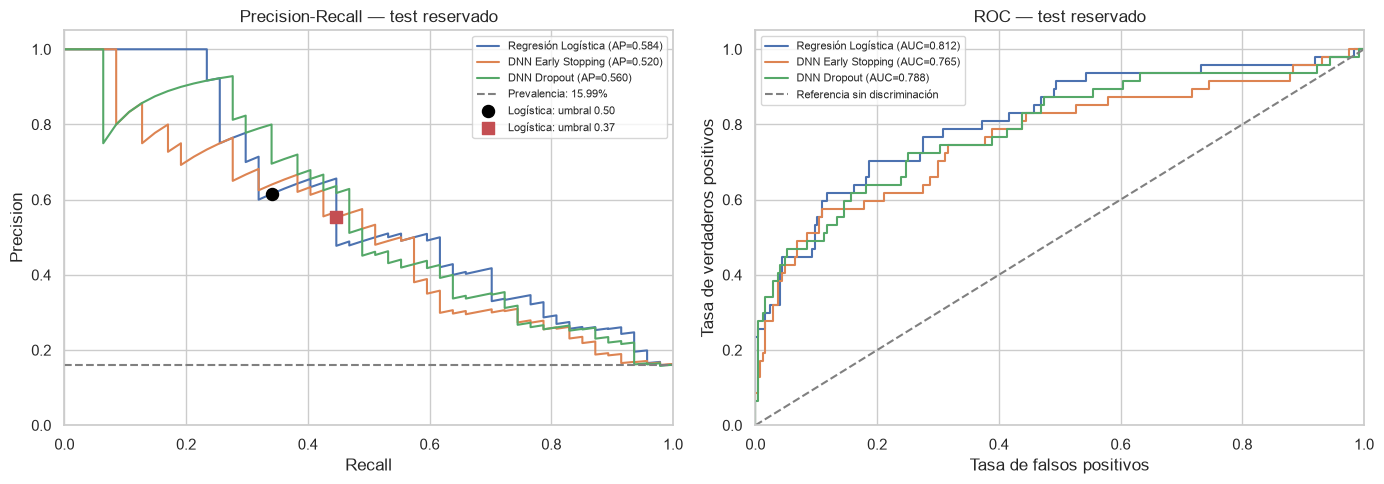

In [25]:
from sklearn.metrics import precision_recall_curve, roc_curve
scores_test = {
    "Regresión Logística": prob_log_test,
    "DNN Early Stopping": prob_early_test,
    "DNN Dropout": prob_dropout_test
}
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for nombre, probabilidades in scores_test.items():
    precision, recall, _ = precision_recall_curve(
        y_test_array, probabilidades
    )
    ap = average_precision_score(
        y_test_array, probabilidades
    )
    axes[0].plot(
        recall,
        precision,
        label=f"{nombre} (AP={ap:.3f})"
    )
    fpr, tpr, _ = roc_curve(
        y_test_array, probabilidades
    )
    auc = roc_auc_score(
        y_test_array, probabilidades
    )
    axes[1].plot(
        fpr,
        tpr,
        label=f"{nombre} (AUC={auc:.3f})"
    )
# Referencia de Precision según prevalencia del test.
axes[0].axhline(
    y_test_array.mean(),
    color="gray",
    linestyle="--",
    label=f"Prevalencia: {y_test_array.mean():.2%}"
)
# Puntos de operación de la misma logística.
for nombre, marcador, color in [
    ("Logística baseline", "o", "black"),
    ("Logística seleccionada", "s", "#C44E52")
]:
    fila = resultados_test.loc[nombre]
    axes[0].scatter(
        fila["Recall"],
        fila["Precision"],
        marker=marcador,
        color=color,
        s=75,
        zorder=5,
        label=f"Logística: umbral {fila['Umbral']:.2f}"
    )
axes[0].set(
    title="Precision-Recall — test reservado",
    xlabel="Recall",
    ylabel="Precision",
    xlim=(0, 1),
    ylim=(0, 1.05)
)
axes[1].plot(
    [0, 1], [0, 1],
    color="gray",
    linestyle="--",
    label="Referencia sin discriminación"
)
axes[1].set(
    title="ROC — test reservado",
    xlabel="Tasa de falsos positivos",
    ylabel="Tasa de verdaderos positivos",
    xlim=(0, 1),
    ylim=(0, 1.05)
)
for ax in axes:
    ax.legend(fontsize=8, loc="best")
plt.tight_layout()
# Guardar la figura para el informe y el repositorio.
carpeta_resultados = Path("results")
carpeta_resultados.mkdir(exist_ok=True)
fig.savefig(
    carpeta_resultados / "curvas_evaluacion_test.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


## 17. Interpretación de la Regresión Logística
Analizamos los coeficientes del pipeline entrenado únicamente
con el conjunto de entrenamiento.
- Coeficiente positivo: contribuye a aumentar el score de abandono.
- Coeficiente negativo: contribuye a disminuirlo.
La interpretación se realiza manteniendo constantes las demás
variables del modelo.
### Precauciones
Las variables numéricas están estandarizadas: sus coeficientes
corresponden a un incremento de una desviación estándar,
no de una unidad original.
Las variables categóricas se representan mediante One-Hot
Encoding sin eliminar una categoría de referencia. Por ello,
sus coeficientes individuales no deben interpretarse como
comparaciones directas contra una categoría base.
Para comparar dos categorías de una misma variable, se considera
la diferencia entre sus coeficientes.
La regularización y las correlaciones entre variables afectan
los coeficientes. Su magnitud absoluta no constituye una medida
universal de importancia ni demuestra causalidad.
Modificar el umbral de clasificación no cambia estos coeficientes.

In [26]:
# Accedemos al pipeline ajustado con entrenamiento.
prep_ajustado = modelo_seleccionado_ml.named_steps[
    "preprocesamiento"
]
logistica_ajustada = modelo_seleccionado_ml.named_steps[
    "modelo"
]
nombres_transformados = (
    prep_ajustado.get_feature_names_out()
)
coeficientes = logistica_ajustada.coef_[0]
tabla_coeficientes = pd.DataFrame({
    "Variable transformada": nombres_transformados,
    "Coeficiente": coeficientes
})
tabla_coeficientes["Magnitud absoluta"] = (
    tabla_coeficientes["Coeficiente"].abs()
)
# Nombres más legibles, conservando el origen de la variable.
tabla_coeficientes["Variable"] = (
    tabla_coeficientes["Variable transformada"]
    .str.replace("numericas__", "", regex=False)
    .str.replace("categoricas__", "", regex=False)
)
coef_positivos = (
    tabla_coeficientes[
        tabla_coeficientes["Coeficiente"] > 0
    ]
    .nlargest(8, "Coeficiente")
)
coef_negativos = (
    tabla_coeficientes[
        tabla_coeficientes["Coeficiente"] < 0
    ]
    .nsmallest(8, "Coeficiente")
)
print("COEFICIENTES POSITIVOS MÁS ALTOS")
print(
    coef_positivos[
        ["Variable", "Coeficiente"]
    ].round(4).to_string(index=False)
)
print("\nCOEFICIENTES NEGATIVOS MÁS BAJOS")
print(
    coef_negativos[
        ["Variable", "Coeficiente"]
    ].round(4).to_string(index=False)
)
tabla_coeficientes.to_csv(
    carpeta_resultados / "coeficientes_logistica.csv",
    index=False
)

COEFICIENTES POSITIVOS MÁS ALTOS
                        Variable  Coeficiente
   JobRole_Laboratory Technician       1.0303
                    OverTime_Yes       0.9161
BusinessTravel_Travel_Frequently       0.8981
    JobRole_Sales Representative       0.8803
  EducationField_Human Resources       0.5997
         YearsSinceLastPromotion       0.5356
              NumCompaniesWorked       0.4834
            MaritalStatus_Single       0.4755

COEFICIENTES NEGATIVOS MÁS BAJOS
                         Variable  Coeficiente
        JobRole_Research Director      -1.0341
                      OverTime_No      -0.9288
        BusinessTravel_Non-Travel      -0.9164
             EducationField_Other      -0.7151
JobRole_Healthcare Representative      -0.5793
                TotalWorkingYears      -0.5204
          EnvironmentSatisfaction      -0.4717
                  JobSatisfaction      -0.4125


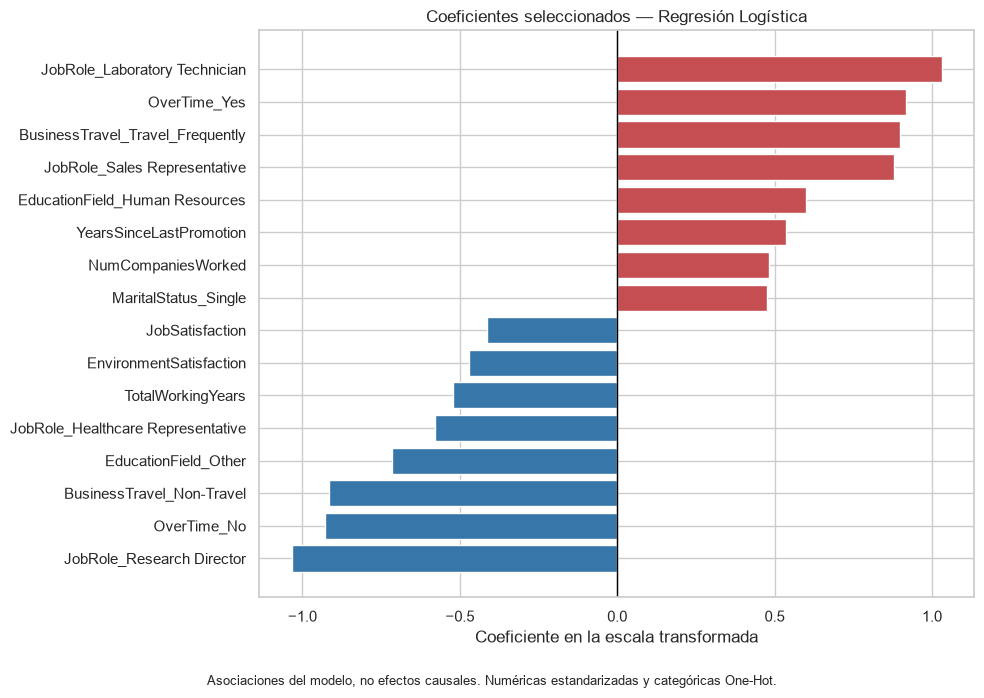

In [27]:
coef_grafico = (
    pd.concat([coef_negativos, coef_positivos])
    .sort_values("Coeficiente")
)
colores = [
    "#C44E52" if valor > 0 else "#3676A8"
    for valor in coef_grafico["Coeficiente"]
]
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(
    coef_grafico["Variable"],
    coef_grafico["Coeficiente"],
    color=colores
)
ax.axvline(0, color="black", linewidth=1)
ax.set(
    title="Coeficientes seleccionados — Regresión Logística",
    xlabel="Coeficiente en la escala transformada",
    ylabel=""
)
fig.text(
    0.5,
    0.01,
    "Asociaciones del modelo, no efectos causales. "
    "Numéricas estandarizadas y categóricas One-Hot.",
    ha="center",
    fontsize=9
)
plt.tight_layout(rect=[0, 0.04, 1, 1])
fig.savefig(
    carpeta_resultados / "coeficientes_logistica.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


### Interpretación de los coeficientes
El modelo asocia las horas extra con un mayor score de abandono.
El coeficiente de OverTime_Yes supera al de OverTime_No,
en concordancia con la asociación descriptiva observada en EDA.
Entre las variables numéricas, mayor tiempo desde la última
promoción y mayor cantidad de empresas anteriores presentan
coeficientes positivos. La experiencia laboral total, la
satisfacción con el entorno y la satisfacción laboral presentan
coeficientes negativos.
Estas asociaciones están condicionadas a las demás variables.
Las numéricas están estandarizadas y las escalas ordinales se
modelaron como numéricas, suponiendo un efecto lineal por nivel.
Los roles y las áreas de formación también muestran diferencias
entre categorías. Sin embargo, sus coeficientes pueden ser
sensibles al tamaño de los grupos, a la regularización y a la
correlación con otras características.
El gráfico muestra coeficientes seleccionados, no una jerarquía
universal de importancia. Las variables numéricas y las categorías
One-Hot no representan incrementos equivalentes.
No se estimaron intervalos de incertidumbre de los coeficientes.
Estos resultados no demuestran causalidad ni justifican acciones
laborales sobre personas o grupos.


## 18. Matrices de confusión sobre test
Comparamos el baseline y la configuración principal utilizando
los mismos empleados de test.
Al reducir el umbral de 0,50 a 0,37:
- Los abandonos detectados aumentan de 16 a 21.
- Los abandonos no detectados disminuyen de 31 a 26.
- Las falsas alertas aumentan de 10 a 17.
El ajuste permite detectar 5 abandonos adicionales a costa de
7 falsas alertas adicionales.
Sin costos de intervención ni evidencia sobre su efectividad,
no podemos afirmar que ese intercambio produzca un beneficio
económico real.

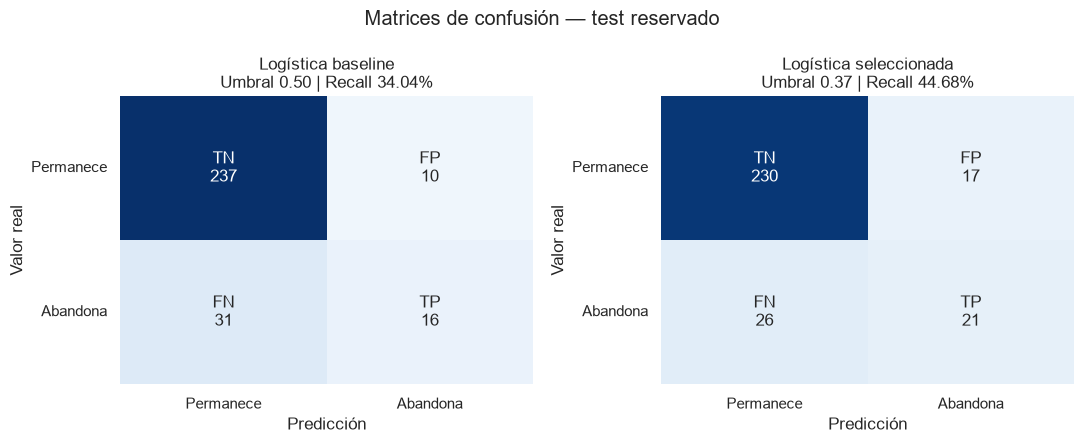

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
configuraciones_matriz = [
    ("Logística baseline", axes[0]),
    ("Logística seleccionada", axes[1])
]
# Escala de color común para comparar ambos gráficos.
max_conteo = int(
    resultados_test.loc[
        ["Logística baseline", "Logística seleccionada"],
        ["TN", "FP", "FN", "TP"]
    ].to_numpy().max()
)
for nombre, ax in configuraciones_matriz:
    fila = resultados_test.loc[nombre]
    matriz = np.array([
        [int(fila["TN"]), int(fila["FP"])],
        [int(fila["FN"]), int(fila["TP"])]
    ])
    anotaciones = np.array([
        [f"TN\n{matriz[0, 0]}", f"FP\n{matriz[0, 1]}"],
        [f"FN\n{matriz[1, 0]}", f"TP\n{matriz[1, 1]}"]
    ])
    sns.heatmap(
        matriz,
        annot=anotaciones,
        fmt="",
        cmap="Blues",
        cbar=False,
        vmin=0,
        vmax=max_conteo,
        xticklabels=["Permanece", "Abandona"],
        yticklabels=["Permanece", "Abandona"],
        ax=ax
    )
    ax.set_title(
        f"{nombre}\n"
        f"Umbral {fila['Umbral']:.2f} | "
        f"Recall {fila['Recall']:.2%}"
    )
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Valor real")
    ax.tick_params(axis="y", rotation=0)
fig.suptitle("Matrices de confusión — test reservado")
plt.tight_layout()
fig.savefig(
    carpeta_resultados / "matrices_confusion_logistica_test.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

## 19. Guardado de modelos y resultados
Guardamos:
- El pipeline completo de la Regresión Logística seleccionada.
- Su umbral de clasificación, definido con predicciones OOF.
- El preprocesador y los modelos de Deep Learning.
- Las tablas de validación y evaluación final.
- Las versiones de las dependencias utilizadas.
El pipeline de Machine Learning incluye el preprocesamiento:
para reutilizarlo deben proporcionarse las variables originales,
no datos previamente escalados o codificados.
El umbral debe conservarse explícitamente: predict() utiliza
el criterio predeterminado del clasificador, no el umbral 0,37
seleccionado en este proyecto.
Los archivos de modelos son artefactos académicos. Su guardado
no implica que estén validados para uso real.

In [29]:
import json
import joblib
carpeta_modelos.mkdir(exist_ok=True)
carpeta_resultados.mkdir(exist_ok=True)
# Pipeline y configuración juntos para evitar perder el umbral.
artefacto_ml = {
    "pipeline": modelo_seleccionado_ml,
    "umbral": umbral_seleccionado_ml,
    "columnas_entrada": X_train_modelo.columns.tolist(),
    "columnas_excluidas": columnas_excluir,
    "clase_positiva": 1,
    "significado_clase_positiva": "Attrition = Yes",
    "configuracion": configuracion_ml
}
ruta_modelo_ml = carpeta_modelos / "logistica_seleccionada.joblib"
joblib.dump(artefacto_ml, ruta_modelo_ml)
# Preprocesador exclusivo de las redes.
joblib.dump(
    preprocesador_dl,
    carpeta_modelos / "preprocesador_dl.joblib"
)
# Ambas redes conservan los mejores pesos de Early Stopping.
dnn_early.save(carpeta_modelos / "dnn_early_final.keras")
dnn_dropout.save(carpeta_modelos / "dnn_dropout_final.keras")
# Metadatos legibles sin cargar los modelos.
metadatos = {
    "configuracion_ml": configuracion_ml,
    "columnas_entrada": X_train_modelo.columns.tolist(),
    "columnas_excluidas": columnas_excluir,
    "umbral_dnn": 0.50,
    "mejor_epoca_dnn_early": mejor_epoca_dnn,
    "mejor_epoca_dnn_dropout": mejor_epoca_dropout,
    "alcance": (
        "Ejercicio académico con datos ficticios. "
        "No validado para decisiones laborales."
    )
}
with open(
    carpeta_modelos / "metadatos.json",
    "w",
    encoding="utf-8"
) as archivo:
    json.dump(
        metadatos,
        archivo,
        ensure_ascii=False,
        indent=2
    )
print("Modelos y metadatos guardados en:", carpeta_modelos.resolve())


Modelos y metadatos guardados en: C:\Users\Noxi-PC\Desktop\tp final\Tp final de curso\Proyecto_Attrition\models


In [30]:
tablas_exportar = {
    "baseline_cv_por_fold.csv": resultados_baseline_folds,
    "comparacion_modelos_cv.csv": comparacion_cv,
    "ranking_por_fold.csv": ranking_por_fold,
    "resumen_ranking_cv.csv": resumen_ranking_cv,
    "exploracion_umbrales_oof.csv": tabla_umbrales,
    "comparacion_dnn_validacion.csv": comparacion_dnn_val,
    "evaluacion_final_test.csv": resultados_test,
    "intervalos_bootstrap_test.csv": intervalos_test,
    "historial_dnn_early.csv": historial_dnn_df,
    "historial_dnn_dropout.csv": historial_dropout_df
}
for nombre_archivo, tabla in tablas_exportar.items():
    tabla.to_csv(
        carpeta_resultados / nombre_archivo,
        index=True,
        encoding="utf-8"
    )
print("Tablas exportadas:")
for nombre_archivo in tablas_exportar:
    print("-", nombre_archivo)

Tablas exportadas:
- baseline_cv_por_fold.csv
- comparacion_modelos_cv.csv
- ranking_por_fold.csv
- resumen_ranking_cv.csv
- exploracion_umbrales_oof.csv
- comparacion_dnn_validacion.csv
- evaluacion_final_test.csv
- intervalos_bootstrap_test.csv
- historial_dnn_early.csv
- historial_dnn_dropout.csv


## 20. Comprobación del artefacto guardado
Recargamos el pipeline y verificamos que reproduzca las
probabilidades y las predicciones obtenidas antes de guardarlo.
Esta es una comprobación técnica de serialización, no una
nueva validación del desempeño ni un ajuste del modelo.

In [31]:
artefacto_recargado = joblib.load(ruta_modelo_ml)
pipeline_recargado = artefacto_recargado["pipeline"]
umbral_recargado = artefacto_recargado["umbral"]
# Respetamos las columnas originales y su orden.
entrada_verificacion = X_test_modelo.loc[
    :, artefacto_recargado["columnas_entrada"]
]
prob_recargadas = pipeline_recargado.predict_proba(
    entrada_verificacion
)[:, 1]
pred_recargadas = (
    prob_recargadas >= umbral_recargado
).astype(int)
np.testing.assert_allclose(
    prob_recargadas,
    prob_log_test,
    rtol=1e-10,
    atol=1e-12
)
np.testing.assert_array_equal(
    pred_recargadas,
    pred_sel_test
)
print("Pipeline recargado: OK")
print(f"Umbral recuperado: {umbral_recargado:.2f}")
print("Probabilidades reproducidas: OK")
print("Predicciones reproducidas: OK")

Pipeline recargado: OK
Umbral recuperado: 0.37
Probabilidades reproducidas: OK
Predicciones reproducidas: OK


In [32]:
import platform
from importlib.metadata import version
dependencias = [
    "numpy",
    "pandas",
    "matplotlib",
    "seaborn",
    "scikit-learn",
    "joblib",
    "tensorflow",
    "ipykernel"
]
contenido_requirements = "\n".join(
    f"{paquete}=={version(paquete)}"
    for paquete in dependencias
) + "\n"
Path("requirements.txt").write_text(
    contenido_requirements,
    encoding="utf-8"
)
entorno = {
    "python": platform.python_version(),
    "sistema": platform.platform(),
    "dependencias": {
        paquete: version(paquete)
        for paquete in dependencias
    }
}
with open(
    carpeta_resultados / "entorno_ejecucion.json",
    "w",
    encoding="utf-8"
) as archivo:
    json.dump(entorno, archivo, ensure_ascii=False, indent=2)
print("requirements.txt generado:")
print(contenido_requirements)
print("Versión de Python:", entorno["python"])

requirements.txt generado:
numpy==2.5.0
pandas==2.3.3
matplotlib==3.11.0
seaborn==0.13.2
scikit-learn==1.9.0
joblib==1.5.3
tensorflow==2.22.0rc0
ipykernel==7.3.0

Versión de Python: 3.14.6


## 22. Conclusiones
La Regresión Logística sin balanceo, con umbral 0,37 seleccionado
mediante predicciones out-of-fold, alcanzó un Recall de 44,68%
en test, frente al 34,04% del baseline con umbral 0,50.
La mejora de 10,64 puntos porcentuales cumple el objetivo
establecido en este test. Permite detectar 5 abandonos adicionales,
a costa de 7 falsas alertas adicionales. El F1 aumenta de
0,4384 a 0,4941.
El intervalo bootstrap aproximado de la mejora es de
2,13 a 19,15 puntos. Por tanto, no podemos garantizar
una mejora poblacional de al menos 8 puntos.
Al priorizar 59 empleados de mayor riesgo, la logística captura
29 de los 47 abandonos: Recall@20% de 61,70%.
Random Forest no aportó una ventaja en la validación realizada.
Las redes tampoco mostraron una mejora clara en las métricas
prioritarias del test bajo los procedimientos implementados.
El principal aprendizaje es que ajustar un modelo simple al
objetivo resulta más útil que aumentar su complejidad sin evidencia.

## 23. Limitaciones y próximos pasos
### Limitaciones
- Datos ficticios y muestra pequeña; el test contiene 47 abandonos.
- Sin fechas para definir un horizonte predictivo ni realizar
  validación temporal.
- Debe verificarse en un caso real que todas las variables
  estén disponibles antes del evento que se quiere predecir.
- Los resultados OOF usados para seleccionar modelo y umbral
  pueden ser optimistas por la propia selección.
- La comparación de ML y DL utiliza procedimientos distintos.
- Las asociaciones y los coeficientes no demuestran causalidad.
- No se evaluaron exhaustivamente equidad, privacidad ni
  estabilidad entre grupos.
- No conocemos los costos de los errores ni la eficacia
  de posibles intervenciones de retención.
### Próximos pasos
- Validar con datos reales, autorizados y representativos.
- Definir horizonte de predicción y disponibilidad de variables.
- Evaluar estabilidad mediante validación anidada o repetida.
- Estudiar calibración, equidad y cambios en la población.
- Evaluar intervenciones por separado de la predicción.
Este proyecto es un ejercicio académico, no un sistema
validado para tomar decisiones laborales.